Add your import statements and the database connection statements in the below code block

In [1]:
#your code here
import pandas as pd
import geopandas as gpd
import numpy as np
import libpysal as ps
import esda
import matplotlib.pyplot as plt
%matplotlib inline  

### **Question 1**:  
Using the Libpysal Data, create a choropleth path of the United States that depicts the per capita income of each US state in 2009.

**Note:** 
* The Libpysal and GeoPandas libraries both contain utility functions that may make this task easier.
* The choropleth map should have the following parameters:
    - legend
    - Title should be '**Per Capita Income of US States on Choropleth Map**'
    - xlabel should be '**US Income**'
* Do not set font size or font-weight for titles and labels and figure size for the plot.

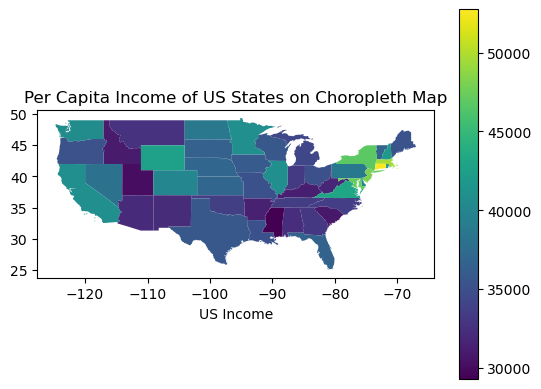

In [2]:
### TEST FUNCTION: test_question1
# DO NOT MODIFY OR REMOVE THE ABOVE LINE
# your code here
us_map = gpd.read_file(ps.examples.get_path("us48.shp"))
us_data = pd.read_csv(ps.examples.get_path("usjoin.csv"))
us_map = us_map.merge(us_data, left_on="STATE_NAME", right_on="Name")
us_map.plot(column="2009", legend = True)
plt.title("Per Capita Income of US States on Choropleth Map")
plt.xlabel("US Income")
plt.show()

### **Question 2**:
Again using the Libpysal Data, create a proportional symbol map showing a dot at the centroid of each state that is scaled to the per capita income of each US state in 2009.

**Note:** 
* The demonstration notebook for this unit contains code that performs a similar task and may be a useful reference for your assignment.
* The proportional symbol map should have the following parameters:
    * Title should be '**Proportional Symbol Map**'
    * xlabel should be '**US Income**'
* Do not set font size or font-weight for titles and labels and figure size for the plot.

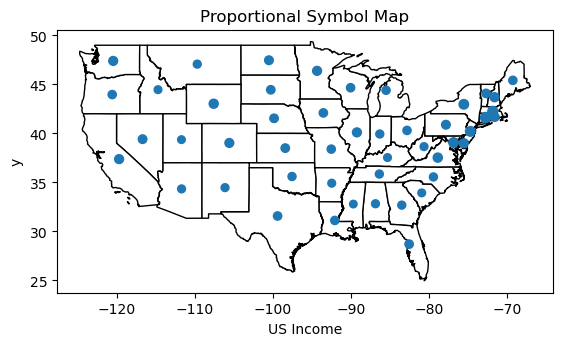

In [3]:
### TEST FUNCTION: test_question2
# DO NOT MODIFY OR REMOVE THE ABOVE 
# your code here
us_map = gpd.read_file(ps.examples.get_path("us48.shp"))
us_data = pd.read_csv(ps.examples.get_path("usjoin.csv"))
us_map = us_map.merge(us_data, left_on="STATE_NAME", right_on="Name")
us_map.set_crs(epsg=4326, inplace=True)
data = us_map.to_crs(epsg=3857)
data["centroid_column"] = data.centroid.to_crs(epsg=4326)  
data["per_cap_income"] = data["2009"]
centroids = list(data["centroid_column"])
df = pd.DataFrame({
    "y": [centroids[i].y for i in range(len(centroids))], 
    "x": [centroids[i].x for i in range(len(centroids))],  
    "data": list(data["per_cap_income"])
})
us_map = us_map.to_crs(epsg=4326)
base = us_map.plot(color="white", edgecolor="black")
df.plot(kind="scatter", x="x", y="y", s=df["data"]/1000, legend = True, ax=base)
plt.title("Proportional Symbol Map")
plt.xlabel("US Income")
plt.show()

### **Question 3**:
Using the same data, compute the value of Moran's I for the per capita income of each US state in 2009 using Rook Continuity. Report the value of I rounded to 4 decimal places (i.e. x.XXXX)

**Note:** 
* You need to merge the two datasets and then apply
Rook Continuity
* Use the `esda` library to calculate the Moran's value.
* To calculate Moran’s I, you need two things: the value of interest (y) and a weight matrix (w).
* Print only the calculated Moran's value rounded to 4 in the code cell below.
* There should only be one print statement in the below cell.

In [4]:
### TEST FUNCTION: test_question3
# DO NOT MODIFY OR REMOVE THE ABOVE 
# your code here
us_map = gpd.read_file(ps.examples.get_path("us48.shp"))
us_data = pd.read_csv(ps.examples.get_path("usjoin.csv"))
us_map = us_map.sort_values(by="STATE_NAME")
us_data = us_data.sort_values(by="Name")
us_map = us_map.merge(us_data, left_on="STATE_NAME", right_on="Name")
y = us_map["2009"].tolist()
w = ps.weights.Rook.from_dataframe(us_map, use_index=False)
w.transform = "r"
mi = esda.Moran(y, w, two_tailed=False)
print("{:.4f}".format(mi.I))

0.4256
